# Modelos: Regresión logística, Naive Bayes y Hist Gradient Boosting
Entreno mis modelos con el preprocesamiento común (`src/utils/modelado.py`) y guardo los resultados en `resultados/`, para compararlos al final con los del resto del grupo.

## 0. Modelos probados y justificación

| Modelo | Tipo | Por qué en este problema |
|---|---|---|
| Regresión logística | Base | En el EDA, cada variable sube o baja un poco el riesgo, siempre en la misma dirección, y casi no se relacionan entre sí. Es una suma de efectos pequeños, justo lo que modela. Además, sus coeficientes se pueden explicar al médico |
| Naive Bayes | Base | Supone que las variables son independientes dentro de cada clase, y en el EDA que realicé apenas se relacionan entre sí |
| HistGradientBoosting | Ensemble | Suma árboles pequeños que corrigen los errores de los anteriores: puede captar efectos no lineales que la logística no ve. Es la versión mejorada de Gradient Boosting y admite `class_weight` para poder comparar con los 3 balanceos |

## 1. Importo librerías y cargo los datos con preprocesamiento

In [61]:
from utils import modelado as mod, constantes as cte
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import ValidationCurveDisplay, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import HistGradientBoostingClassifier

%matplotlib inline

# misma partición 80/20 estratificada que el resto del grupo; X_test no se usa en este notebook
X_train, X_test, y_train, y_test = mod.cargar_datos()
print(f"Train: {X_train.shape[0]} pacientes y {X_train.shape[1]} variables | Test: {X_test.shape[0]} pacientes")
print("Proporción de clases en train:", y_train.value_counts(normalize=True).sort_index().round(2).to_dict())

Train: 1803 pacientes y 30 variables | Test: 451 pacientes
Proporción de clases en train: {0: 0.5, 1: 0.3, 2: 0.2}


## 2. Modelos por defecto con cada balanceo

Como acordamos en nuestra última reunión y siguiendo el pipeline de `modelado.py` probamos los 3 balanceos de la pipeline con los parámetros por defecto. Naive Bayes no tiene un parámetro de semilla, por lo que no se rellena.

In [54]:
modelos = {
    "logistica": LogisticRegression(random_state=cte.semilla),
    "naive_bayes": GaussianNB(),
    "hist_gradient_boosting": HistGradientBoostingClassifier(random_state=cte.semilla),
    "suelo": DummyClassifier(strategy="most_frequent"),
}

balanceos = [None, "class_weight", "smotenc"]
filas = []
pipeline = {}
busqueda_por_defecto = {}
for nombre, modelo in modelos.items():
    for balanceo in balanceos:
        etiqueta = f"{nombre}_{balanceo or "sin_balanceo"}"
        # el suelo solo se mide sin balanceo: siempre predice la clase mayoritaria, así que balancear no aporta nada
        if nombre == "suelo" and balanceo is not None:
            continue
        try:
            pipeline[etiqueta] = mod.crear_pipeline(modelo, balanceo)
        except ValueError:
            print(f"El modelo {nombre} no admite {balanceo} como parámetro. Se omite.")
            continue
        busqueda_por_defecto[etiqueta] = mod.crear_busqueda(pipeline[etiqueta], {}).fit(X_train, y_train)
        
por_defecto = pd.concat([mod.tabla_resultados(b, etiqueta) for etiqueta, b in busqueda_por_defecto.items()])

# train frente a validación: el sobreajuste se ve en la diferencia, sin tocar el test
columnas = ["f1_macro_train", "f1_macro_val", "f1_macro_val_std", "recall_alto_val",
            "precision_alto_val", "diferencia_train_val"]
por_defecto[columnas].sort_values("f1_macro_val", ascending=False).round(3)

El modelo naive_bayes no admite class_weight como parámetro. Se omite.


,f1_macro_train,f1_macro_val,f1_macro_val_std,recall_alto_val,precision_alto_val,diferencia_train_val
modelo,,,,,,
logistica_class_weight,0.673,0.648,0.037,0.737,0.636,0.025
logistica_sin_balanceo,0.674,0.645,0.026,0.670,0.693,0.029
naive_bayes_sin_balanceo,0.664,0.641,0.039,0.684,0.653,0.023
logistica_smotenc,0.666,0.637,0.031,0.753,0.622,0.030
hist_gradient_boosting_sin_balanceo,1.000,0.629,0.027,0.634,0.680,0.371
hist_gradient_boosting_smotenc,1.000,0.624,0.030,0.687,0.642,0.376
hist_gradient_boosting_class_weight,1.000,0.621,0.033,0.657,0.637,0.379
naive_bayes_smotenc,0.633,0.602,0.029,0.734,0.580,0.031
suelo_sin_balanceo,0.222,0.222,0.000,0.000,0.000,0.000


**Conclusión.**

- **Todos superan con mucho al suelo** (F1 macro de 0,22: acierta a todos los de riesgo bajo y a ninguno más).

- **La regresión logística y Naive Bayes apenas sobreajustan:** entre 0,02 y 0,03 de diferencia entre train y validación.

- **HistGradientBoosting memoriza el train:** F1 de 1,0 en train frente a 0,62-0,63 en validación, con los tres balanceos. Necesita regularización, y es lo que busca su rejilla (apartado 5).

- **Balancear sube el recall de riesgo alto:** en la logística pasa de 0,67 a 0,74-0,75 con `class_weight` o SMOTENC, sin bajar el F1 macro.

- No elijo aquí el balanceo: con los valores por defecto la comparación no es justa (por ejemplo, HistGradientBoosting memoriza con los tres). Lo decido en cada apartado, con los hiperparámetros ajustados.

A continuación procedo a ajustar los hiperparámetros de cada modelo

In [20]:
# los mejores parámetros son un texto largo: así pandas no lo corta con "..."
pd.set_option("display.max_colwidth", None)


def ajustar_modelo(nombre, modelo, parametros, balanceos=balanceos):
    """Ajusta la rejilla con cada balanceo y devuelve (búsquedas, tabla comparativa).

    nombre: prefijo de las filas, p. ej. "logistica" -> "logistica_smotenc".
    parametros: rejilla con el prefijo "modelo__", p. ej. {"modelo__C": [0.1, 1]}.
    """
    busquedas, filas = {}, []
    for balanceo in balanceos:
        # misma etiqueta que en el apartado 2, para comparar con los valores por defecto
        etiqueta = f"{nombre}_{balanceo or 'sin_balanceo'}"
        try:
            pipeline = mod.crear_pipeline(modelo, balanceo)
        except ValueError:
            # p. ej. GaussianNB no admite class_weight: se salta ese balanceo
            print(f"El modelo {nombre} no admite {balanceo} como parámetro. Se omite.")
            continue
        # crear_busqueda pone la validación, la semilla y las métricas comunes del grupo
        busquedas[etiqueta] = mod.crear_busqueda(pipeline, parametros).fit(X_train, y_train)
        filas.append(mod.tabla_resultados(busquedas[etiqueta], etiqueta))

    # mismas columnas que en el apartado 2 y, además, la mejor combinación de cada balanceo
    tabla = pd.concat(filas)[columnas + ["mejores_parametros"]]
    return busquedas, tabla.sort_values("f1_macro_val", ascending=False)


def por_fold(busquedas, metricas=("f1_macro", "recall_alto")):
    """Nota de la mejor combinación de cada balanceo en cada fold: como los folds son los mismos, se comparan por pares."""
    columnas = {}
    for metrica in metricas:
        for balanceo, b in busquedas.items():
            columnas[(metrica, str(balanceo))] = [b.cv_results_[f"split{k}_test_{metrica}"][b.best_index_]
                                                  for k in range(cte.n_folds)]
    tabla = pd.DataFrame(columnas)
    tabla.index.name = "fold"
    return tabla

# Misma función que la usada por Rodri pero, añadiendo la opción de escala logarítmica en el eje x, que es útil para la regularización de la regresión logística.
def curva_validacion(busqueda, parametro, valores, titulo, escala_log=False):
    """Train y validación (media ± desviación) al mover un hiperparámetro, con el resto en su mejor valor."""
    ValidationCurveDisplay.from_estimator(
        busqueda.best_estimator_, X_train, y_train,
        param_name=parametro, param_range=valores,
        cv=mod.validador, scoring=mod.metrica,      # mismos folds y misma métrica que la búsqueda
        std_display_style="fill_between", n_jobs=-1)
    plt.xscale("log" if escala_log else "linear")
    plt.title(titulo)
    plt.ylabel("F1 macro")                         # en la leyenda, "Test" es el fold de validación
    plt.show()

## 3. Regresión logística

Hiperparámetros:

- `C`: *inversa de la fuerza de la regularización*. Un valor alto indica una regularización débil o nula, permitiendo un modelo más complejo, mientras que uno pequeño lo simplifica. Pruebo de 0,001 a 100.
- `l1_ratio`: *tipo de regularización*. Un valor 0 aplica una penalización L2 pura (Ridge), que mantiene todos los coeficientes pero los reduce suavemente. Mientras que el valor 1 hace lo propio con L1 (Lasso), que tiende a producir modelos dispersos a llevar algunos coeficientes a cero mediante selección de características.
- Selecciono `saga` como solver, dado que admite L1, L2 y Elastic-Net. `liblinear` soporta L1 y L2 pero es paea clasificación binaria y el valor por predeterinado `lbfgs`solo soporta L2.
- `max_iter` aunque no es un hiperparámetro es el límite de pasos del optimizaor hasta que el modelo converge, conviene tenerlo alto para optimizar aunque depende del solver.

In [4]:
parametros_logistica = {
    "modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "modelo__l1_ratio": [0, 0.5, 1],
}

logistica = LogisticRegression(solver="saga", max_iter=5000, random_state=cte.semilla)

busquedas_logistica, tabla_logistica = ajustar_modelo("logistica", logistica, parametros_logistica)
tabla_logistica.round(3)

,f1_macro_train,f1_macro_val,f1_macro_val_std,recall_alto_val,precision_alto_val,diferencia_train_val,mejores_parametros
modelo,,,,,,,
logistica_class_weight,0.675,0.651,0.034,0.748,0.631,0.024,"{'modelo__C': 0.1, 'modelo__l1_ratio': 0}"
logistica_sin_balanceo,0.671,0.647,0.027,0.670,0.691,0.025,"{'modelo__C': 0.1, 'modelo__l1_ratio': 0}"
logistica_smotenc,0.667,0.637,0.029,0.753,0.622,0.030,"{'modelo__C': 1, 'modelo__l1_ratio': 0}"


In [11]:
por_fold(busquedas_logistica).round(3)

f1_macro                                           \
     logistica_sin_balanceo logistica_class_weight logistica_smotenc   
fold                                                                   
0                     0.667                  0.678             0.660   
1                     0.684                  0.662             0.641   
2                     0.615                  0.611             0.608   
3                     0.648                  0.693             0.675   
4                     0.618                  0.612             0.600   

                recall_alto                                           
     logistica_sin_balanceo logistica_class_weight logistica_smotenc  
fold                                                                  
0                     0.681                  0.722             0.736  
1                     0.712                  0.767             0.753  
2                     0.583                  0.667             0.653  
3                     0.694                  0.847             0.861  
4                     0.681                  0.736             0.764

In [16]:
# balanceo elegido (ver la conclusión del apartado)
busqueda_logistica = busquedas_logistica["logistica_class_weight"]
mod.guardar_resultados(busqueda_logistica, "logistica")
print("Mejores parámetros:", busqueda_logistica.best_params_)

Mejores parámetros: {'modelo__C': 0.1, 'modelo__l1_ratio': 0}


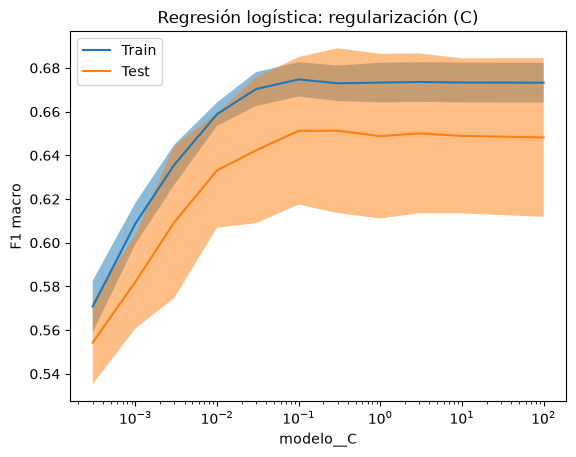

In [21]:
curva_validacion(busqueda_logistica, "modelo__C", [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100],
                 "Regresión logística: regularización (C)", escala_log=True)

**Coeficientes.** Es la ventaja de la logística: se puede leer qué variables suben o bajan el riesgo alto. Muestro los coeficientes de la clase de riesgo alto. En las numéricas, el coeficiente es el efecto de subir un rango intercuartílico (por el `RobustScaler`); en las binarias, el de pasar de 0 a 1.

In [33]:
modelo_logistica = busqueda_logistica.best_estimator_.named_steps["modelo"]
nombres = busqueda_logistica.best_estimator_.named_steps["preprocesado"].get_feature_names_out()
for n in range(0,3):
    print(f"Clase {n}:")
    display(pd.Series(modelo_logistica.coef_[n], index=nombres).sort_values(ascending=False).round(3))

Clase 0:


num__frecuencia_ejercicio_semanal       0.329
num__colesterol_hdl                     0.323
cat__nivel_actividad                    0.304
num__clearance_creatinina               0.303
num__horas_sueno_diarias                0.196
cat__dieta_vegetariana                  0.029
num__frecuencia_cardiaca_reposo        -0.059
num__colesterol_total                  -0.099
cat__dieta_baja_en_carbohidratos       -0.130
num__trigliceridos                     -0.216
num__anos_fumador                      -0.218
num__presion_diastolica                -0.229
num__colesterol_ldl                    -0.230
cat__antecedentes_familiares_materno   -0.230
num__perimetro_cintura                 -0.233
num__presion_sistolica                 -0.248
num__edad                              -0.266
num__proteina_c_reactiva               -0.282
num__indice_masa_corporal              -0.305
num__acido_urico                       -0.326
cat__tratamiento_estatinas             -0.359
num__glucosa_ayunas               

Clase 1:


cat__dieta_vegetariana                  0.231
cat__fumador_actual                     0.130
num__clearance_creatinina               0.091
cat__diabetes_mellitus                  0.089
num__frecuencia_ejercicio_semanal       0.060
cat__dieta_occidental                   0.046
cat__antecedentes_familiares_paterno    0.032
num__presion_diastolica                 0.027
cat__uso_antihipertensivos              0.018
num__proteina_c_reactiva                0.018
num__frecuencia_cardiaca_reposo         0.015
num__colesterol_ldl                     0.006
num__horas_sueno_diarias                0.005
num__anos_fumador                       0.004
num__glucosa_ayunas                     0.004
cat__dieta_baja_en_carbohidratos       -0.002
cat__tratamiento_estatinas             -0.003
num__colesterol_hdl                    -0.014
num__indice_masa_corporal              -0.018
cat__antecedentes_familiares_materno   -0.018
num__edad                              -0.027
num__trigliceridos                

Clase 2:


num__consumo_alcohol_semanal            0.773
cat__dieta_occidental                   0.567
cat__hipertension_previa                0.533
num__hemoglobina_glicosilada            0.529
cat__antecedentes_familiares_paterno    0.519
cat__diabetes_mellitus                  0.474
cat__uso_antihipertensivos              0.432
num__acido_urico                        0.404
cat__tratamiento_estatinas              0.362
num__glucosa_ayunas                     0.356
num__presion_sistolica                  0.324
num__indice_masa_corporal               0.322
num__edad                               0.293
cat__fumador_actual                     0.293
num__perimetro_cintura                  0.291
num__proteina_c_reactiva                0.264
num__trigliceridos                      0.251
cat__antecedentes_familiares_materno    0.248
num__colesterol_ldl                     0.225
num__anos_fumador                       0.214
num__presion_diastolica                 0.202
num__colesterol_total             

Evaluamos principalmente sobre la clase de riesgo alto, dado que es la clase más crítica a predecir, porque es el error más costoso: categorizar a un paciente que tiene riesgo cardivascular alto, dentro de otro grupo

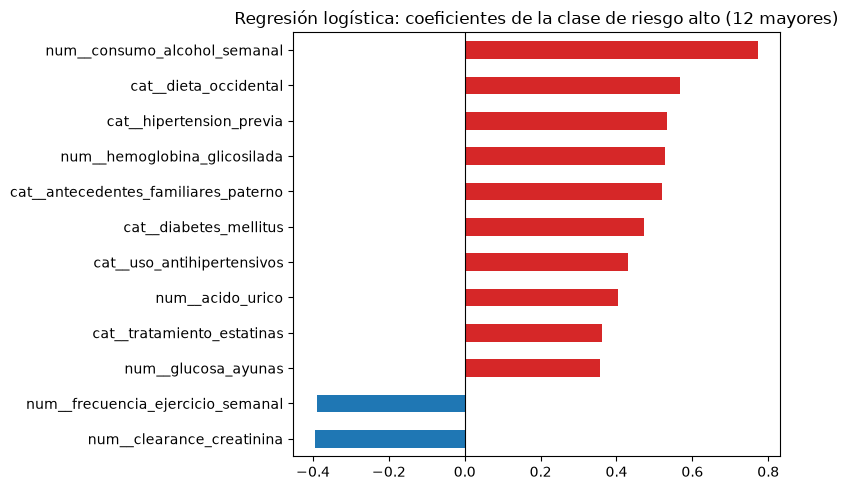

In [ ]:
modelo_logistica = busqueda_logistica.best_estimator_.named_steps["modelo"]
nombres = busqueda_logistica.best_estimator_.named_steps["preprocesado"].get_feature_names_out()

coef_alto = pd.Series(modelo_logistica.coef_[2], index=nombres)   # fila 2 = clase de riesgo alto
top = coef_alto.reindex(coef_alto.abs().sort_values(ascending=False).index).head(12)
top.sort_values().plot.barh(figsize=(8, 5), color=np.where(top.sort_values() > 0, "tab:red", "tab:blue"))
plt.title("Regresión logística: coeficientes de la clase de riesgo alto (12 mayores)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Conclusión:**

- Los mejores parámetros para modelo de regresión logística son: `class_weight`, `C = 0,1` y regularización L2 (`l1_ratio = 0`)

-  F1 macro de 0,651 ± 0,034 en validación, recall de riesgo alto de 0,748 y precisión de riesgo alto de 0,631.

- **Elijo `class_weight`** porque gana en F1 macro a SMOTENC en los 5 folds con el mismo recall de alto (cada uno gana en algunos folds, con diferencias de 0,01-0,03). Frente a no balancear, empata en F1 y sube el recall de alto en los 5 folds (de 0,67 a 0,75 de media). Además, no crea pacientes sintéticos.

- **No sobreajusta:** 0,675 en train frente a 0,651 en validación.

- **La curva de `C`** muestra el subajuste por la izquierda: con `C` menor de 0,01 la regularización es tan fuerte que train y validación bajan juntos. A partir de 0,1 se estabiliza, y dar más libertad al modelo no mejora la validación.

- **L1 no mejora:** la búsqueda se queda con L2 con los tres balanceos, así que no compensa dejar variables a 0.

- **Coeficientes:** lo que más sube el riesgo alto es el consumo de alcohol, seguido de la dieta occidental, la hipertensión previa, la hemoglobina glicosilada y los antecedentes paternos. Lo que más lo baja es el ejercicio semanal y el aclaramiento de creatinina. Coincide con lo que vimos en el EDA, pero es importante tener en cuenta en las numéricas el coeficiente es por rango intercuartílico y en las binarias por pasar de 0 a 1, así que sus tamaños no se comparan directamente.

## 4. Naive Bayes

Uso `GaussianNB`, que supone que cada variable sigue una normal dentro de cada clase. Solo tiene un hiperparámetro que ajustar:

- `var_smoothing`: suma a todas las varianzas una fracción de la varianza más grande. Evita que una variable con muy poca varianza en una clase domine la probabilidad, y suaviza las colas largas que vimos en el EDA. Pruebo de 10⁻⁹ (el valor por defecto) a 1, en escala logarítmica.

Naive Bayes no admite `class_weight`: comparo sin balancear frente a SMOTENC.

In [39]:
parametros_bayes = {"modelo__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 1]}

busquedas_naive_bayes, tabla_naive_bayes = ajustar_modelo("naive_bayes", GaussianNB(), parametros_bayes,
                                                              balanceos=(None, "smotenc"))
tabla_naive_bayes.round(3)

,f1_macro_train,f1_macro_val,f1_macro_val_std,recall_alto_val,precision_alto_val,diferencia_train_val,mejores_parametros
modelo,,,,,,,
naive_bayes_sin_balanceo,0.664,0.643,0.043,0.684,0.657,0.021,{'modelo__var_smoothing': 0.001}
naive_bayes_smotenc,0.650,0.627,0.029,0.751,0.603,0.023,{'modelo__var_smoothing': 0.1}


In [40]:
por_fold(busquedas_naive_bayes).round(3)

f1_macro                                  recall_alto  \
     naive_bayes_sin_balanceo naive_bayes_smotenc naive_bayes_sin_balanceo   
fold                                                                         
0                       0.667               0.654                    0.667   
1                       0.697               0.648                    0.767   
2                       0.573               0.592                    0.569   
3                       0.655               0.648                    0.681   
4                       0.622               0.591                    0.736   

                          
     naive_bayes_smotenc  
fold                      
0                  0.722  
1                  0.781  
2                  0.667  
3                  0.819  
4                  0.764

In [42]:
busqueda_naive_bayes = busquedas_naive_bayes["naive_bayes_smotenc"]
mod.guardar_resultados(busqueda_naive_bayes, "naive_bayes")
print("Mejores parámetros:", busqueda_naive_bayes.best_params_)

Mejores parámetros: {'modelo__var_smoothing': 0.1}


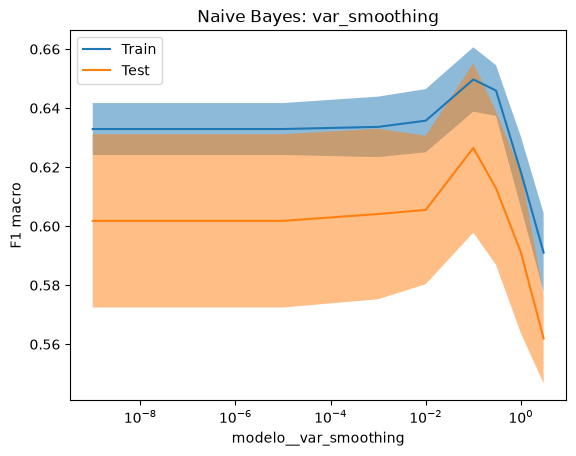

In [43]:
curva_validacion(busqueda_naive_bayes, "modelo__var_smoothing", [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 0.3, 1, 3],
                 "Naive Bayes: var_smoothing", escala_log=True)

**Conclusión.**

- **La mejor combinación** es SMOTENC con `var_smoothing = 0,1`: F1 macro de 0,627 ± 0,029, recall de riesgo alto de 0,751 y precisión de riesgo alto de 0,603.

- **Elijo SMOTENC con el criterio acordado.** Sin balancear tiene algo más de F1 macro (0,643 frente a 0,627), pero la diferencia queda dentro de la desviación entre folds. En ese caso decide el recall de alto, y SMOTENC lo sube en los 5 folds (de 0,68 a 0,75). El coste es más falsas alarmas: la precisión de riesgo alto baja de 0,66 a 0,60.

- **`var_smoothing` sí importa con SMOTENC:** la curva tiene un máximo en 0,1 (de 0,60 a 0,63 en validación). Por encima de 1 las varianzas quedan tan infladas que el modelo deja de distinguir las clases.

- **No sobreajusta:** 0,650 en train frente a 0,627 en validación.

## 5. HistGradientBoosting

Con los hiperparámetros por defecto memoriza el train (F1 de 1,0), así que con esta optimización intentamos frenar el sobreaprendizaje:

- `learning_rate`: cuánto corrige cada árbol los errores de los anteriores. Más bajo, aprendizaje más lento y menos sobreajuste.

- `max_iter`: número de árboles. Va de la mano del `learning_rate`: con uno bajo hacen falta más árboles.

- `max_depth`: profundidad de cada árbol. Árboles de 2 o 3 niveles captan interacciones sencillas entre variables; `None` deja el límite en el número de hojas (31 por defecto).

- `min_samples_leaf`: pacientes mínimos por hoja (20 por defecto). Más pacientes, árboles más simples.

- `l2_regularization`: penaliza los valores grandes en las hojas, otra forma de frenar el sobreajuste.

Son 48 combinaciones por balanceo, así que tarda unos 5 mins:

In [44]:
parametros_hgb = {
    "modelo__learning_rate": [0.03, 0.1],
    "modelo__max_iter": [100, 300],
    "modelo__max_depth": [2, 3, None],
    "modelo__min_samples_leaf": [20, 50],
    "modelo__l2_regularization": [0, 1],
}
hgb = HistGradientBoostingClassifier(random_state=cte.semilla)

busquedas_hgb, tabla_hgb = ajustar_modelo("hist_gradient_boosting", hgb, parametros_hgb)
tabla_hgb.round(3)

,f1_macro_train,f1_macro_val,f1_macro_val_std,recall_alto_val,precision_alto_val,diferencia_train_val,mejores_parametros
modelo,,,,,,,
hist_gradient_boosting_class_weight,0.934,0.645,0.027,0.723,0.642,0.289,"{'modelo__l2_regularization': 1, 'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__max_iter': 100, 'modelo__min_samples_leaf': 20}"
hist_gradient_boosting_sin_balanceo,0.940,0.642,0.024,0.657,0.680,0.298,"{'modelo__l2_regularization': 1, 'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__max_iter': 100, 'modelo__min_samples_leaf': 20}"
hist_gradient_boosting_smotenc,0.917,0.638,0.027,0.720,0.644,0.279,"{'modelo__l2_regularization': 0, 'modelo__learning_rate': 0.1, 'modelo__max_depth': 2, 'modelo__max_iter': 300, 'modelo__min_samples_leaf': 50}"


In [45]:
por_fold(busquedas_hgb).round(3)

f1_macro                                      \
     hist_gradient_boosting_sin_balanceo hist_gradient_boosting_class_weight   
fold                                                                           
0                                  0.641                               0.645   
1                                  0.639                               0.673   
2                                  0.608                               0.601   
3                                  0.683                               0.673   
4                                  0.641                               0.633   

                                                            recall_alto  \
     hist_gradient_boosting_smotenc hist_gradient_boosting_sin_balanceo   
fold                                                                      
0                             0.632                               0.639   
1                             0.672                               0.658   
2                             0.605                               0.639   
3                             0.665                               0.653   
4                             0.615                               0.694   

                                                                         
     hist_gradient_boosting_class_weight hist_gradient_boosting_smotenc  
fold                                                                     
0                                  0.694                          0.708  
1                                  0.753                          0.753  
2                                  0.681                          0.639  
3                                  0.722                          0.764  
4                                  0.764                          0.736

In [47]:
busqueda_hgb = busquedas_hgb["hist_gradient_boosting_class_weight"]
mod.guardar_resultados(busqueda_hgb, "hist_gradient_boosting")
print("Mejores parámetros:", busqueda_hgb.best_params_)

Mejores parámetros: {'modelo__l2_regularization': 1, 'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__max_iter': 100, 'modelo__min_samples_leaf': 20}


Las 5 mejores combinaciones, con su F1 en train, para ver si alguna es casi igual de buena pero sobreajusta menos:

In [50]:
resultados_hgb = pd.DataFrame(busqueda_hgb.cv_results_)
columnas_param = [c for c in resultados_hgb if c.startswith("param_")]
resultados_hgb[columnas_param + ["mean_train_f1_macro", "mean_test_f1_macro", "std_test_f1_macro"]] \
    .sort_values("mean_test_f1_macro", ascending=False).head(5).round(3)

,param_modelo__l2_regularization,param_modelo__learning_rate,param_modelo__max_depth,param_modelo__max_iter,param_modelo__min_samples_leaf,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro
40,1,0.10,3,100,20,0.934,0.645,0.027
30,1,0.03,3,300,20,0.925,0.644,0.026
7,0,0.03,3,300,50,0.912,0.644,0.024
17,0,0.10,3,100,50,0.925,0.644,0.027
38,1,0.10,2,300,20,0.942,0.643,0.031


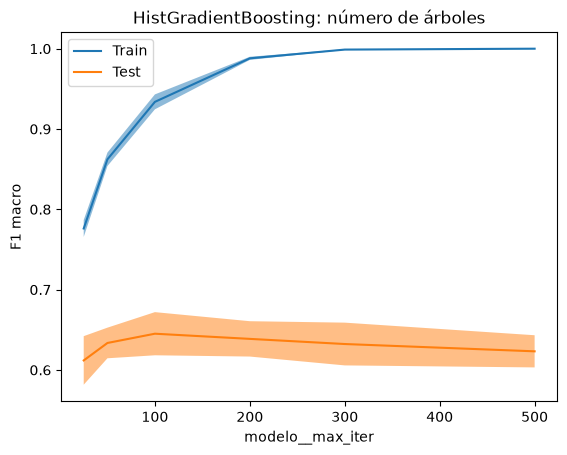

In [48]:
curva_validacion(busqueda_hgb, "modelo__max_iter", [25, 50, 100, 200, 300, 500], "HistGradientBoosting: número de árboles")

**Conclusión.**

- **La mejor combinación** es `class_weight`, `learning_rate = 0,1`, 100 árboles de profundidad 3, 20 pacientes por hoja y `l2_regularization = 1`: F1 macro de 0,645 ± 0,027, recall de riesgo alto de 0,723 y precisión de riesgo alto de 0,642.

- **Elijo `class_weight`:** frente a no balancear, empata en F1 y sube el recall de alto en los 5 folds (de 0,66 a 0,72). Frente a SMOTENC, gana en F1 en 4 de los 5 folds y empata en recall.

- **El ajuste mejora el modelo por defecto:** de 0,621 a 0,645 en validación, con árboles más pequeños y regularizados.

- **Pero sigue sobreajustando:** 0,934 en train frente a 0,645 en validación. Entre las 5 mejores combinaciones no hay ninguna igual de buena que sobreajuste menos (todas tienen más de 0,91 en train). La curva lo explica: la validación tiene su máximo en unos 100 árboles y después baja un poco, mientras que el train sigue subiendo hasta 1,0. Los árboles que se añaden solo memorizan pacientes.

## 6. Comparación de mis modelos

Junto la mejor versión de cada modelo con el suelo. El criterio es el que acordamos: F1 macro y, si dos modelos quedan dentro de la desviación entre folds, el recall de riesgo alto.

In [ ]:
# balanceo elegido en cada apartado y la búsqueda ajustada con él
balanceo_elegido = {"logistica": "class_weight", "naive_bayes": "smotenc", "hist_gradient_boosting": "class_weight"}
mis_modelos = {"logistica": busqueda_logistica, "naive_bayes": busqueda_naive_bayes,
               "hist_gradient_boosting": busqueda_hgb}
# el suelo solo está como referencia: cualquier modelo útil tiene que superarlo
busquedas = {"suelo": busqueda_por_defecto["suelo_sin_balanceo"], **mis_modelos}

# una fila por modelo ajustado: train y validación (media ± desviación) y mejores parámetros
comparacion = pd.concat([mod.tabla_resultados(b, nombre) for nombre, b in busquedas.items()])
comparacion["balanceo"] = pd.Series({"suelo": "sin_balanceo", **balanceo_elegido})

# versión por defecto con el mismo balanceo: ya está en `por_defecto` (apartado 2), no hace falta reentrenar
etiquetas = {nombre: f"{nombre}_{balanceo}" for nombre, balanceo in balanceo_elegido.items()}
defecto = por_defecto.loc[list(etiquetas.values()), ["f1_macro_val", "recall_alto_val", "diferencia_train_val"]]
defecto.index = list(etiquetas)                    # "logistica_class_weight" -> "logistica"
comparacion = comparacion.join(defecto.add_suffix("_por_defecto"))
comparacion["mejora_f1_ajuste"] = comparacion["f1_macro_val"] - comparacion["f1_macro_val_por_defecto"]

# 1.er criterio: F1 macro en validación
comparacion = comparacion.sort_values("f1_macro_val", ascending=False)
mejor = comparacion.iloc[0]

# empate: el F1 del modelo queda dentro de la desviación entre folds del mejor
umbral = mejor["f1_macro_val"] - mejor["f1_macro_val_std"]
comparacion["empata_en_f1"] = comparacion["f1_macro_val"] >= umbral

# 2.º criterio: entre los empatados manda el recall de riesgo alto; el resto sigue ordenado por F1
mejor_recall = comparacion.loc[comparacion.loc[comparacion["empata_en_f1"], "recall_alto_val"].idxmax()]
comparacion["empata_en_recall"] = comparacion["empata_en_f1"] & (
    comparacion["recall_alto_val"] >= mejor_recall["recall_alto_val"] - mejor_recall["recall_alto_val_std"])
comparacion = comparacion.sort_values(["empata_en_f1", "recall_alto_val"], ascending=False)

print(f"Empatan en F1 macro los modelos con F1 >= {umbral:.3f} "
      f"({mejor.name}: {mejor['f1_macro_val']:.3f} ± {mejor['f1_macro_val_std']:.3f})")
columnas_criterio = ["balanceo", "f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std",
                     "precision_alto_val", "f1_macro_train", "diferencia_train_val", "empata_en_f1", "empata_en_recall"]
comparacion[columnas_criterio].round(3)

In [ ]:
por_fold(mis_modelos).round(3)

f1_macro                                  recall_alto            \
     naive_bayes logistica hist_gradient_boosting naive_bayes logistica   
fold                                                                      
0          0.654     0.678                  0.645       0.722     0.722   
1          0.648     0.662                  0.673       0.781     0.767   
2          0.592     0.611                  0.601       0.667     0.667   
3          0.648     0.693                  0.673       0.819     0.847   
4          0.591     0.612                  0.633       0.764     0.736   

                             
     hist_gradient_boosting  
fold                         
0                     0.694  
1                     0.753  
2                     0.681  
3                     0.722  
4                     0.764

**¿Cuánto aporta el ajuste?** Comparo cada modelo ajustado con su versión por defecto con el mismo balanceo, que ya tenía en la tabla `por_defecto` del apartado 2.

In [ ]:
# misma tabla de comparación: columnas por defecto frente a ajustado (el suelo no se ajusta, se deja fuera)
columnas_ajuste = ["f1_macro_val_por_defecto", "f1_macro_val", "mejora_f1_ajuste",
                   "recall_alto_val_por_defecto", "recall_alto_val",
                   "diferencia_train_val_por_defecto", "diferencia_train_val"]
comparacion.loc[list(mis_modelos), columnas_ajuste].round(3)

**Matriz de confusión en validación.** El recall de riesgo alto no distingue si a un paciente de riesgo alto lo clasifico como moderado o como bajo, que es mucho más grave. Con `cross_val_predict`, a cada paciente del train lo predice el modelo del fold en el que estaba en validación, así que no uso el test.

In [ ]:
fig, axes = plt.subplots(1, len(mis_modelos), figsize=(15, 4))
for ax, (nombre, busqueda) in zip(axes, mis_modelos.items()):
    y_pred = cross_val_predict(busqueda.best_estimator_, X_train, y_train, cv=mod.validador, n_jobs=-1)
    # normalize="true": cada fila suma 1, así la diagonal es el recall de cada clase
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred, display_labels=["bajo", "moderado", "alto"],
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    alto_como_bajo = ((y_train == 2) & (y_pred == 0)).sum()
    # el error más grave también va a la tabla, para que quede en el CSV
    comparacion.loc[nombre, "alto_como_bajo"] = alto_como_bajo
    ax.set_title(f"{nombre}\n(alto clasificado como bajo: {alto_como_bajo})")
plt.tight_layout()
plt.show()

In [ ]:
# tabla completa (criterio, ajuste, errores graves y mejores parámetros) para la memoria;
# nombre propio para no pisar los CSV por modelo que lee el resto del grupo
comparacion.to_csv(mod.RUTA_RESULTADOS / "comparacion_pablo.csv")
print("Guardado en", mod.RUTA_RESULTADOS / "comparacion_pablo.csv")

**Conclusión.**

| | Regresión logística | Naive Bayes | HistGradientBoosting |
|---|---|---|---|
| F1 macro (validación) | **0,651 ± 0,034** | 0,627 ± 0,029 | 0,645 ± 0,027 |
| Recall de riesgo alto | 0,748 | **0,751** | 0,723 |
| Riesgo alto clasificado como bajo (de 361) | **8 (2 %)** | 9 (2 %) | 15 (4 %) |
| Precisión de riesgo alto | 0,631 | 0,603 | **0,642** |
| Diferencia train-validación | 0,024 | **0,023** | 0,289 |
| Balanceo | `class_weight` | SMOTENC | `class_weight` |

- **Mi candidato es la regresión logística** (`class_weight`, `C = 0,1`, L2). Supera a Naive Bayes en F1 macro en los 5 folds, así que esa ventaja es real. Frente a HistGradientBoosting gana en 3 de los 5 folds: es un empate, y lo desempata el recall de riesgo alto (0,748 frente a 0,723). Además comete la mitad de errores graves (8 pacientes de riesgo alto clasificados como bajo, frente a 15), no sobreajusta y se puede explicar con sus coeficientes.
- **Un modelo lineal y sencillo iguala al boosting.** Encaja con lo que vimos en el EDA: el riesgo parece una suma de efectos pequeños, sin interacciones fuertes que solo un modelo de árboles pueda captar.
- **La clase difícil es la de riesgo moderado** en los tres modelos (recall de 0,47-0,50): se confunde con las otras dos, como ya mostraba el solapamiento del EDA.
- **El ajuste aporta poco a la logística** (0,648 → 0,651: sus valores por defecto ya eran buenos), algo más a Naive Bayes (0,602 → 0,627, gracias a `var_smoothing`) y sobre todo a HistGradientBoosting (0,621 → 0,645, con menos sobreajuste: 0,38 → 0,29).
- Los tres modelos ajustados quedan guardados en `resultados/` (`logistica`, `naive_bayes` e `hist_gradient_boosting`) para la comparación final del grupo, que es donde se evalúa en test el modelo elegido.